# Seminar 1: Optimizing Conference Paper Assignment Using Genetic Algorithms

The goal of assignment was to construct a genetic algorithm optimizing Conference Paper Assignment. For the problem we are optimizing, we are given certain constraints and preferences. The initial constraints are the number of papers each reviewer can handle, the number of reviews each paper needs, friendship relationships between reviewers to prevent conflicts of interest (e.g., friends reviewing the same paper), and authorship constraints where reviewers cannot review papers they have authored.

The data that our algorithm will have as an input is:
- Number of Papers (int)
- Number of Reviewers (int)
- Reviewer Capacity (int)
- Review Requirements per Paper [int, int]
- Authorship Matrix (binary)
- Preference Matrix (int)
- Friendship Matrix (binary)

The result our algorithm will give:
- Assignment Matrix (binary)

### The basic algorithm structure

In [1]:
import pygad
from scipy.stats import norm
import matplotlib.pyplot as plt
import json
import numpy as np

In [2]:
dataset_id = 0
num_papers = 0
num_reviewers = 0
reviewer_capacity = 0
min_reviews_per_paper = 0
max_reviews_per_paper = 0
preferences = np.array([])
friendship = np.array([])
authorship = np.array([])

def load_dataset(path):
    global dataset_id, num_papers, num_reviewers, reviewer_capacity, min_reviews_per_paper, max_reviews_per_paper, preferences, friendship, authorship
    with open(path, "r") as file:
        data = json.load(file)

    # Extract information
    dataset_id = data["dataset_id"]
    num_papers = data["num_papers"]
    num_reviewers = data["num_reviewers"]
    reviewer_capacity = data["reviewer_capacity"]
    min_reviews_per_paper = data["min_reviews_per_paper"]
    max_reviews_per_paper = data["max_reviews_per_paper"]
    preferences = np.array(data["preferences"])
    friendship = np.array(data["friendships"])
    authorship = np.array(data["authorship"])

The fitness function will determine the quality of solutions. The fitness function that will be used to evaluate all subsequent algorithms is ```eval_ff(solution, param1, param2, ...)```

In [3]:
def eval_ff(solution, preferences, num_reviewers, num_papers, max_reviews_per_paper, min_reviews_per_paper, reviewer_capacity, authorship, friendship, verbose = 1):
    # Weights for constraint penalties
    # review limit per paper
    rlpp = 10
    # paper limit per reviewer
    plpr = 10
    # friendship constraint
    fc = 20
    # authorship constraint
    ac = 50

    assignment = solution.reshape(num_reviewers, num_papers)

    # Satisfaction score
    satisfaction = np.sum(assignment * preferences)

    # Constraints penalties
    penalties = 0

    for j in range(num_papers):
        if np.sum(assignment[:, j]) < min_reviews_per_paper or np.sum(assignment[:, j]) > max_reviews_per_paper:
            if verbose == 1:
                print("Num papers constraint fail. Column: ", j)
            penalties += rlpp

    # Paper limit per reviewer
    for i in range(num_reviewers):
        if np.sum(assignment[i, :]) > reviewer_capacity:
            if verbose == 1:
                print("Paper limit per reviewer constraint fail. Row: ", i)
            penalties += plpr

    # Friendship constraint
    for j in range(num_papers):
        reviewers = np.where(assignment[:, j] == 1)[0]
        for r1 in reviewers:
            for r2 in reviewers:
                if friendship[r1, r2] == 1:
                    if verbose == 1:
                        print("Friendship constraint fail. Reviewers: ", r1, " and ", r2)
                    penalties += fc

    # Authorship constraint
    if np.any(assignment * authorship):
        if verbose == 1:
            print("Authorship constraint fail: Indices ", np.nonzero(assignment * authorship))
        penalties += ac
        
    if verbose == 1:
        print("Score:", satisfaction - penalties)

    return satisfaction - penalties
    

The same will also be the structure of fitness function for the basic algorithm

In [4]:
# Fitness function
def fitness_func(ga_instance, solution, solution_idx):
    # Penalty weights
    rlpp = 10
    plpr = 10
    fc = 20
    ac = 50

    assignment = solution.reshape(num_reviewers, num_papers)

    # Satisfaction score
    satisfaction = np.sum(assignment * preferences)

    # Constraints penalties
    penalties = 0

    # Review limit per paper
    for j in range(num_papers):
        if np.sum(assignment[:, j]) < min_reviews_per_paper or np.sum(assignment[:, j]) > max_reviews_per_paper:
            penalties += rlpp

    # Paper limit per reviewer
    for i in range(num_reviewers):
        if np.sum(assignment[i, :]) > reviewer_capacity:
            penalties += plpr

    # Friendship constraint
    for j in range(num_papers):
        reviewers = np.where(assignment[:, j] == 1)[0]
        for r1 in reviewers:
            for r2 in reviewers:
                if friendship[r1, r2] == 1:
                    penalties += fc

    # Authorship constraint
    if np.any(assignment * authorship):
        penalties += ac

    return satisfaction - penalties

For the penalty weights we chose such that the authorship constraint is penalized the most, followed by friendship constraint and then review per paper and papers per reviewer constraints.

In [5]:
load_dataset("../datasets/easy_dataset_1.json")

### Running the algorithm

In [6]:
# Genetic Algorithm setup
binary_gene_space = [0,1]

ga_instance = pygad.GA(
    num_generations=20,
    num_parents_mating=20,
    fitness_func=fitness_func,
    sol_per_pop=1000,
    num_genes=num_reviewers * num_papers,
    gene_type=int,
    gene_space=binary_gene_space,
    mutation_type="swap", 
    crossover_type="uniform", 
    mutation_probability=0.2
)

# Run the GA
ga_instance.run()

# Best solution
best_solution, solution_fitness, _ = ga_instance.best_solution()
assignment = best_solution.reshape(num_reviewers, num_papers)
print("Best Assignment:\n", assignment)
print("Fitness Value: ", solution_fitness)

/home/matjaz/.conda/envs/IS/lib/python3.13/site-packages/pygad/pygad.py:1139: UserWarning: The 'delay_after_gen' parameter is deprecated starting from PyGAD 3.3.0. To delay or pause the evolution after each generation, assign a callback function/method to the 'on_generation' parameter to adds some time delay.
  warnings.warn("The 'delay_after_gen' parameter is deprecated starting from PyGAD 3.3.0. To delay or pause the evolution after each generation, assign a callback function/method to the 'on_generation' parameter to adds some time delay.")


Best Assignment:
 [[1 1 1 1 1]
 [1 0 1 1 0]
 [0 1 0 0 1]
 [0 0 1 1 0]
 [1 1 0 0 1]]
Fitness Value:  37


In [7]:
eval_ff(best_solution, preferences, num_reviewers, num_papers, max_reviews_per_paper, min_reviews_per_paper, reviewer_capacity, authorship, friendship)

Paper limit per reviewer constraint fail. Row:  0
Score: 37


np.int64(37)

For the ```easy_dataset_1``` we converge at the score of approx. 37, breaking one constraint. \
\
Further on we will be comparing scores on medium problems, allowing us to quickly enough collect some average scores while dealing with moderately challenging problem.

For harder problems, we can try to solve them using some other methods, providing a benchmark for further genetic algorithms. Linear programming problem solver from ```python pulp``` library was used to construct a solver included in Appendix. \
\
For ```medium_problem_1``` we find a full solution (breaking no constraint) that receives a high fitness score. The score of around 107 for this medium difficulty dataset therefore defines a good fitness score.

In [8]:
load_dataset("../datasets/medium_dataset_1.json")

Average and highest score for 20 runs:

In [9]:
def test_algorithm(num_iter, ga_config, initial_seed = 0):
    avg = 0
    seed = initial_seed
    max_sol = 0
    best_sol = 0

    for i in range(num_iter):
        seed += 1
        ga_config['random_seed'] = seed
        
        ga_instance = pygad.GA(
            **ga_config
        )
        ga_instance.run()

        best_solution, best_solution_fitness, _ = ga_instance.best_solution()
        best_ff = eval_ff(best_solution, preferences, num_reviewers, num_papers, max_reviews_per_paper, min_reviews_per_paper, reviewer_capacity, authorship, friendship, verbose=0)
        print(best_ff)
        avg += best_ff
        if (best_ff> max_sol):
            max_sol = best_ff
            best_sol = best_solution

    return (avg/num_iter, max_sol, best_sol)

In [10]:
ga_config = {
    'num_generations': 20,
    'num_parents_mating': 20,
    'fitness_func': fitness_func,
    'sol_per_pop': 1000,
    'num_genes': num_reviewers * num_papers,
    'gene_type': int,
    'gene_space': binary_gene_space,
    'mutation_type': "swap",
    'crossover_type': "uniform",
    'mutation_probability': 0.2
}

In [11]:
avg, max_sol, best_sol = test_algorithm(20, ga_config)
print("avg", avg, "max", max_sol)

40
49
24
56
45
45
43
49
81
42
15
47
85
28
69
33
88
81
50
31
avg 50.05 max 88


In [12]:
eval_ff(best_sol, preferences, num_reviewers, num_papers, max_reviews_per_paper, min_reviews_per_paper, reviewer_capacity, authorship, friendship)

Paper limit per reviewer constraint fail. Row:  5
Score: 88


np.int64(88)

The basic algorithm converges by generation number 10

In [13]:
ga_instance = pygad.GA(
    **ga_config
)
ga_instance.run()

best_sol, best_solution_fitness, _ = ga_instance.best_solution()

/home/matjaz/.conda/envs/IS/lib/python3.13/site-packages/pygad/visualize/plot.py:109: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  matplotlib.pyplot.legend()


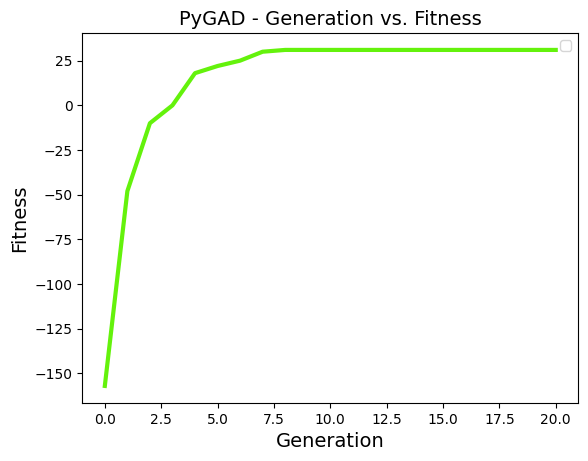

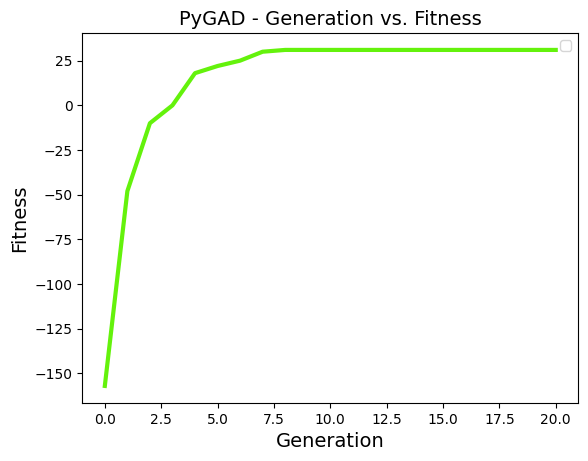

In [14]:
ga_instance.plot_fitness()

## Mutation and Crossover

For an improved version of our algorithm, we can try to produce offspring that satisfies constraints. Repairing offspring solutions for all constraints except review number per paper requirements is trivial. Just erasing conflicting assignments ensures the constraints are met. \
\
Our algorithm will optimize with respect to reviews per paper and preference score, therefore the fitness function can be simplified

In [15]:
def fitness_func(ga_instance, solution, solution_idx):
    assignment = solution.reshape(num_reviewers, num_papers)
    
    # Penalty weights
    rlpp = 10

    # Satisfaction score
    satisfaction = np.sum(assignment * preferences)
    
    # Constraints penalties
    penalties = 0
    
    # Review limit per paper
    for j in range(num_papers):
        if np.sum(assignment[:, j]) < min_reviews_per_paper or np.sum(assignment[:, j]) > max_reviews_per_paper:
            penalties += rlpp
    
    return satisfaction - penalties

Functions to check solutions and repair them if needed. Initial population is checked as well.

In [16]:
def check(ga_instance, children):
    # Repair children
    for idx, child in enumerate(children):
        matr = np.reshape(child, (num_reviewers, num_papers))
        if not is_valid_assignment(matr):
            children[idx] = repair_solution(matr).reshape(-1)
    return children

def check_initial(ga_instance):
    # Repair initial population
    for solution_idx, solution in enumerate(ga_instance.population):
        assignment = solution.reshape((num_reviewers, num_papers))
        if not is_valid_assignment(assignment):
            ga_instance.population[solution_idx] = repair_solution(assignment).reshape(-1)

# Validity checks (constraints)
def is_valid_assignment(assignment):
    # Check paper reviews (min and max reviews per paper)  - Skipped because with our correction algorithm, we are not fixing this constraint 
    #
    # paper_counts = np.sum(assignment, axis=0)
    # if any(paper_counts < min_reviews_per_paper) or any(paper_counts > max_reviews_per_paper):
    #     return False
    
    # Check reviewer capacities
    reviewer_counts = np.sum(assignment, axis=1)
    if any(reviewer_counts > reviewer_capacity):
        return False
    
    # Check authorship constraints (a reviewer cannot review their own paper)
    if np.any(assignment & authorship):
        return False

    # Check friendship constraints (no two friends should review the same paper)
    for i in range(num_reviewers):
        for j in range(num_reviewers):
            if friendship[i][j] == 1:
                for k in range(num_papers):
                    if assignment[i][k] == 1 and assignment[j][k] == 1:
                        return False

    return True

# Repair function to correct an invalid solution
def repair_solution(assignment):
    # Ensure reviewer capacities are respected
    reviewer_counts = np.sum(assignment, axis=1)
    for i in range(num_reviewers):
        if reviewer_counts[i] > reviewer_capacity:
            for j in range(num_papers):
                if assignment[i][j] == 1:
                    assignment[i][j] = 0
                    reviewer_counts = np.sum(assignment, axis=1)
                    if reviewer_counts[i] <= reviewer_capacity:
                        break
    
    # Ensure friendship constraints are respected
    for i in range(num_reviewers):
        for j in range(num_reviewers):
            if friendship[i][j] == 1:
                for k in range(num_papers):
                    if assignment[i][k] == 1 and assignment[j][k] == 1:
                        assignment[i][k] = 0  # Remove one of them
                        break
    
    # Ensure authorship constraints are respected
    assignment *= (1-authorship)
    
    return assignment

In [17]:
ga_config = {
    'num_generations': 20,
    'num_parents_mating': 20,
    'fitness_func': fitness_func,
    'sol_per_pop': 1000,
    'num_genes': num_reviewers * num_papers,
    'gene_type': int,
    'gene_space': binary_gene_space,
    'mutation_type': "swap",
    'crossover_type': "uniform",
    'mutation_probability': 0.2,
    'on_start': check_initial,
    'on_mutation': check,
    'on_crossover': check
}

In [18]:
avg, max_sol, best_sol = test_algorithm(20, ga_config)
print("avg", avg, "max", max_sol)

71
79
78
80
76
85
86
73
88
83
78
96
78
72
89
76
61
93
70
81
avg 79.65 max 96


In [19]:
eval_ff(best_sol, preferences, num_reviewers, num_papers, max_reviews_per_paper, min_reviews_per_paper, reviewer_capacity, authorship, friendship)

Num papers constraint fail. Column:  1
Score: 96


np.int64(96)

The repair routine substantially increases the scores

The new algoritm converges by generation number 10

In [20]:
ga_instance = pygad.GA(
    **ga_config
)
ga_instance.run()

best_sol, best_solution_fitness, _ = ga_instance.best_solution()

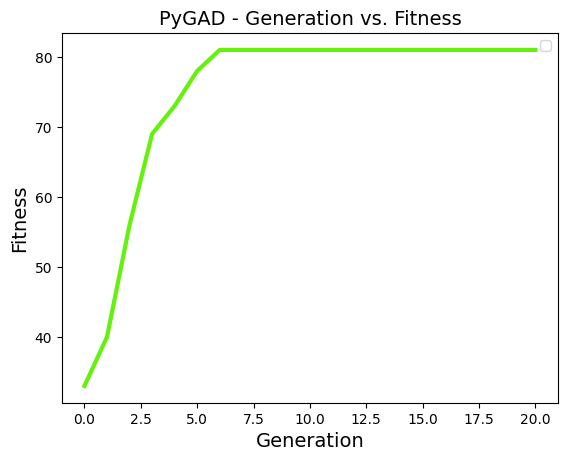

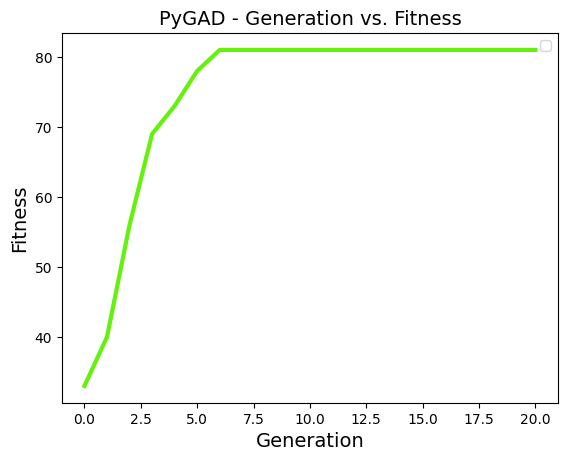

In [21]:
ga_instance.plot_fitness()

## Complexity and Diversity

Keeping diversity in population is cruicial, as the algorithm searches a broader solution space. For this we can for example add a new constraint or requirement or promote exploration with repairing only a portion of population. \
\
Introducing a new constraint on top of current repair functions does not provide much improvement since we are still constraining our population to the initial constraints we want to satisfy.\
Similarly, repairing only a portion of population on its own does not provide improvement probably because we are still scoring based only on initial constraints. \
\
Combining the two approaches however, showed some improvement, since we are promoting searching broader in solution space while enabling more exploration.\
The new fitness function will include a new constraint: spread of preferences across reviewers(The preferences should be satisfied equally).

With this configuration the parameters that worked best were:\
repair_chance = 0.8\
spread_weight = 0.2

In [22]:
# a chance to repair a constraint
repair_chance = 0.8
# a weight of additional points for new constraint
spread_weight = 0.2

In [23]:
def fitness_func(ga_instance, solution, solution_idx):
    global spread_weight
    assignment = solution.reshape(num_reviewers, num_papers)
    
    # Penalty weights
    rlpp = 10
    plpr = 10
    fc = 20
    ac = 50

    # Satisfaction score (primary objective)
    satisfaction = np.sum(assignment * preferences)
    
    # Secondary objective: maximize the spread of preferences across reviewers
    spread_score = 0
    for i in range(num_reviewers):
        # Get the preferences for papers assigned to reviewer i
        assigned_papers = np.where(assignment[i] == 1)[0]
        if len(assigned_papers) > 0:
            reviewer_preferences = preferences[i, assigned_papers]
            # Calculate the variance of preferences
            mean_preference = np.mean(reviewer_preferences)
            variance = np.var(reviewer_preferences)
            spread_score += variance  # Add variance to the spread score
    
    # Constraints penalties (primary objective constraints)
    penalties = 0
    
    # Review limit per paper
    for j in range(num_papers):
        if np.sum(assignment[:, j]) < min_reviews_per_paper or np.sum(assignment[:, j]) > max_reviews_per_paper:
            penalties += rlpp
    
    # Paper limit per reviewer
    for i in range(num_reviewers):
        if np.sum(assignment[i, :]) > reviewer_capacity:
            penalties += plpr
    
    # Friendship constraint
    for j in range(num_papers):
        reviewers = np.where(assignment[:, j] == 1)[0]
        for r1 in reviewers:
            for r2 in reviewers:
                if friendship[r1, r2] == 1:
                    penalties += fc
    
    # Authorship constraint
    if np.any(assignment * authorship):
        penalties += ac
    
    # The final fitness is the primary objective (satisfaction) plus the secondary objective (spread_score)
    # We want to maximize both objectives, so we add the spread score to the satisfaction
    # The spread score can also be scaled if necessary, e.g., by a constant factor
    return satisfaction + spread_weight * spread_score - penalties

The repair function will now repair each assignment (entry in assignment matrix) only with certain probability ```repair_chance```

In [24]:
# Repair function to correct an invalid solution
def repair_solution(assignment):
    global repair_chance
    # Ensure reviewer capacities are respected
    reviewer_counts = np.sum(assignment, axis=1)
    for i in range(num_reviewers):
        if reviewer_counts[i] > reviewer_capacity:
            for j in range(num_papers):
                if assignment[i][j] == 1 and np.random.rand() < repair_chance:
                    assignment[i][j] = 0
                    reviewer_counts = np.sum(assignment, axis=1)
                    if reviewer_counts[i] <= reviewer_capacity:
                        break
    
    # Ensure friendship constraints are respected
    for i in range(num_reviewers):
        for j in range(num_reviewers):
            if friendship[i][j] == 1:
                for k in range(num_papers):
                    if assignment[i][k] == 1 and assignment[j][k] == 1 and np.random.rand() < repair_chance:
                        assignment[i][k] = 0  # Remove one of them
                        break
    
    # Ensure authorship constraints are respected
    for i in range(num_reviewers):
        for j in range(num_papers):
            if authorship[i, j] == 1 and assignment[i, j] == 1 and np.random.rand() < repair_chance:
                assignment[i, j] = 0

    return assignment

This approach converges slower than previous, so we need to increase the ```num_generations``` parameter and with that time complexity as well.

In [25]:
ga_config = {
    'num_generations': 20,
    'num_parents_mating': 20,
    'fitness_func': fitness_func,
    'sol_per_pop': 1000,
    'num_genes': num_reviewers * num_papers,
    'gene_type': int,
    'gene_space': binary_gene_space,
    'mutation_type': "swap",
    'crossover_type': "uniform",
    'mutation_probability': 0.2,
    'on_start': check_initial,
    'on_mutation': check,
    'on_crossover': check,
}

In [26]:
avg, max_sol, best_sol = test_algorithm(10, ga_config)
print("avg", avg, "max", max_sol)

80
93
92
79
83
79
86
67
83
83
avg 82.5 max 93


In [27]:
eval_ff(best_sol, preferences, num_reviewers, num_papers, max_reviews_per_paper, min_reviews_per_paper, reviewer_capacity, authorship, friendship)

Num papers constraint fail. Column:  0
Score: 93


np.int64(93)

The new algorithm converges by generation number 10 as well, but is slower.

In [28]:
ga_instance = pygad.GA(
    **ga_config
)
ga_instance.run()

best_sol, best_solution_fitness, _ = ga_instance.best_solution()

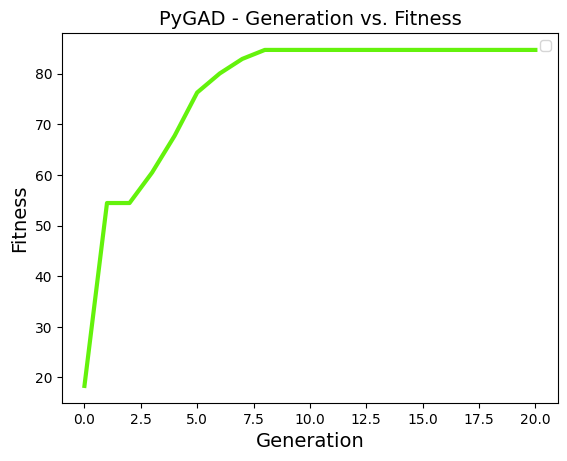

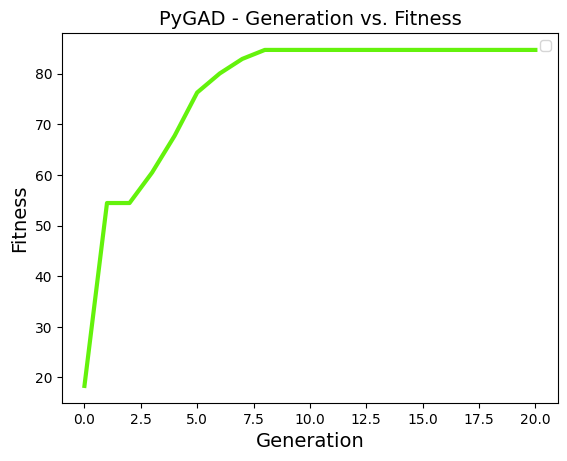

In [29]:
ga_instance.plot_fitness()

### General repair function

Since we are trying to broaden exploration in solution space, we already repair only a certain part of population. We can now try to repair all constraints at once. \
\
With this configuration the parameters that worked best were:\
repair_chance = 0.2\
spread_weight = 0.8

In [30]:
# a chance to repair a constraint
repair_chance = 0.2
# a weight of additional points for new constraint
spread_weight = 0.8

In [31]:
# Validity checks (constraints)
def is_valid_assignment(assignment):
    for i in range(num_reviewers):
        reviewer_count = np.sum(assignment[i])
        if reviewer_count > reviewer_capacity:
            for j in range(num_papers):
                if assignment[i, j] == 1:
                    return False
    
    # 2. Paper review requirements (each paper needs between min_reviews_per_paper and max_reviews_per_paper reviews)
    for j in range(num_papers):
        paper_count = np.sum(assignment[:, j])
        
        # Ensure the paper has at least min_reviews_per_paper reviews
        if paper_count < min_reviews_per_paper:
            for i in range(num_reviewers):
                if assignment[i, j] == 0:
                    return False
        
        # Remove excess reviewers from the paper if it exceeds max_reviews_per_paper
        if paper_count > max_reviews_per_paper:
            for i in range(num_reviewers):
                if assignment[i, j] == 1 and paper_count > max_reviews_per_paper:
                    return False
    
    # 3. Friendship constraints (no two friends should review the same paper)
    for i in range(num_reviewers):
        for j in range(i + 1, num_reviewers):
            if friendship[i, j] == 1:
                for k in range(num_papers):
                    if assignment[i, k] == 1 and assignment[j, k] == 1:
                        return False
    
    # 4. Authorship constraints (reviewers cannot review their own papers)
    for i in range(num_reviewers):
        for j in range(num_papers):
            if authorship[i, j] == 1:
                return False

    return True

# Repair function to correct an invalid solution
def repair_solution(assignment):
    global repair_chance

    # Ensure the offspring meet the constraints
    # 1. Reviewer capacity (max reviews per reviewer)
    for i in range(num_reviewers):
        reviewer_count = np.sum(assignment[i])
        if reviewer_count > reviewer_capacity:
            for j in range(num_papers):
                if assignment[i, j] == 1 and reviewer_count > reviewer_capacity and np.random.rand() < repair_chance:
                    assignment[i, j] = 0
                    reviewer_count -= 1
    
    # 2. Paper review requirements (each paper needs between min_reviews_per_paper and max_reviews_per_paper reviews)
    for j in range(num_papers):
        paper_count = np.sum(assignment[:, j])
        
        # Ensure the paper has at least min_reviews_per_paper reviews
        if paper_count < min_reviews_per_paper:
            for i in range(num_reviewers):
                if assignment[i, j] == 0 and np.random.rand() < repair_chance:
                    assignment[i, j] = 1
                    paper_count += 1
                    if paper_count >= min_reviews_per_paper:
                        break
        
        # Remove excess reviewers from the paper if it exceeds max_reviews_per_paper
        if paper_count > max_reviews_per_paper:
            for i in range(num_reviewers):
                if assignment[i, j] == 1 and paper_count > max_reviews_per_paper and np.random.rand() < repair_chance:
                    assignment[i, j] = 0
                    paper_count -= 1
    
    # 3. Friendship constraints (no two friends should review the same paper)
    for i in range(num_reviewers):
        for j in range(i + 1, num_reviewers):
            if friendship[i, j] == 1:
                for k in range(num_papers):
                    if assignment[i, k] == 1 and assignment[j, k] == 1:
                        # Swap one reviewer's assignment to a different paper
                        for l in range(num_papers):
                            if assignment[i, l] == 0 and np.random.rand() < repair_chance:
                                assignment[i, l] = 1
                                assignment[i, k] = 0
                                break
    
    # 4. Authorship constraints (reviewers cannot review their own papers)
    for i in range(num_reviewers):
        for j in range(num_papers):
            if authorship[i, j] == 1 and np.random.rand() < repair_chance:
                assignment[i, j] = 0

    return assignment

In [32]:
ga_config = {
    'num_generations': 30,
    'num_parents_mating': 20,
    'fitness_func': fitness_func,
    'sol_per_pop': 1000,
    'num_genes': num_reviewers * num_papers,
    'gene_type': int,
    'gene_space': binary_gene_space,
    'mutation_type': "swap",
    'crossover_type': "uniform",
    'mutation_probability': 0.2,
    'on_start': check_initial,
    'on_mutation': check,
    'on_crossover': check,
}

In [33]:
avg, max_sol, best_sol = test_algorithm(10, ga_config)
print("avg", avg, "max", max_sol)

96
104
94
95
97
97
96
97
99
91
avg 96.6 max 104


In [34]:
eval_ff(best_sol, preferences, num_reviewers, num_papers, max_reviews_per_paper, min_reviews_per_paper, reviewer_capacity, authorship, friendship)

Score: 104


np.int64(104)

The new algorithm also converges by generation 10, but is the slowest.

In [35]:
ga_instance = pygad.GA(
    **ga_config
)
ga_instance.run()

best_sol, best_solution_fitness, _ = ga_instance.best_solution()

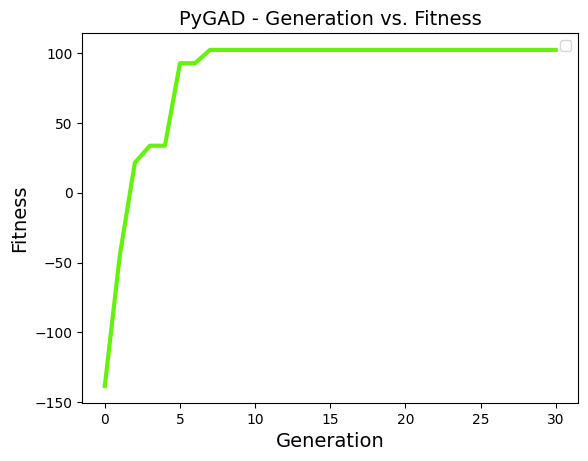

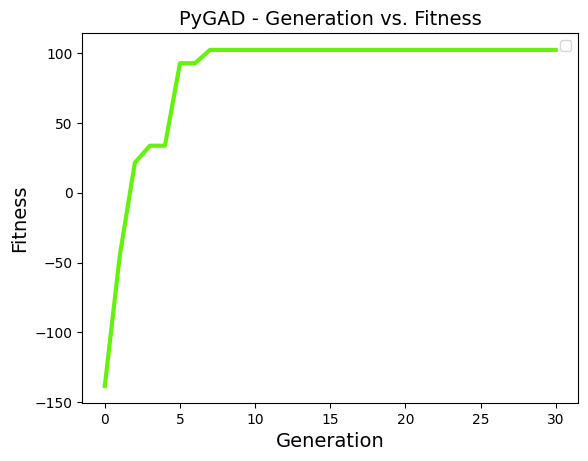

In [36]:
ga_instance.plot_fitness()

The current algorithm is able to solve the problem without breaking any initial constraints. It also showed to be very robust on harder datasets. All of hard datasets
are fully solveable regarding initial constraints and our algorithm is able to find the solution for all datasets.

In [37]:
load_dataset("../datasets/hard_dataset_4.json")

In [38]:
ga_config = {
    'num_generations': 30,
    'num_parents_mating': 20,
    'fitness_func': fitness_func,
    'sol_per_pop': 1000,
    'num_genes': num_reviewers * num_papers,
    'gene_type': int,
    'gene_space': binary_gene_space,
    'mutation_type': "swap",
    'crossover_type': "uniform",
    'mutation_probability': 0.2,
    'on_start': check_initial,
    'on_mutation': check,
    'on_crossover': check,
}

In [39]:
ga_instance = pygad.GA(
    **ga_config
)

# Run the GA
ga_instance.run()

# Best solution
best_solution, solution_fitness, _ = ga_instance.best_solution()
assignment = best_solution.reshape(num_reviewers, num_papers)
print("Best Assignment:\n", assignment)
eval_ff(best_solution, preferences, num_reviewers, num_papers, max_reviews_per_paper, min_reviews_per_paper, reviewer_capacity, authorship, friendship)

Best Assignment:
 [[1 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 0 0 0]
 [0 1 1 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0]
 [0 0 1 0 0 0 1 1 0 0 1 0 1 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1]
 [0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 0 0 0 0 1 1 1 1 0 0 1 0]
 [0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 1 1 0 0 0 1 1 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 1 1 0 1 1 0 1 0 0 1 0 1 0 0 0 0 0 0 1 0 0 1 0]
 [1 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 1 0 0 1 0]
 [0 0 1 0 0 0 0 1 0 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 1 1 0 0]
 [1 1 1 0 0 0 1 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0]
 [0 0 0 1 1 1 0 0 0 1 0 0 0 0 0 0 0 1

np.int64(256)

### Further improvements

the algorithm is very good at finding a solution that satisfies all constraints, which was the most important goal. However, there is still room for improvement regarding the preference score. For ```hard_dataset_4``` for example, the linear programming solver finds a solution with the score of approx. 470.\
\
So far we have not really changed the parameters such as ```num_parents_mating, sol_per_pop, mutation_type, crossover_type, parent_selection_type, keep_elitism and mutation_probability```. All changes made with respect to the current configuration showed to perform way worse or equal, but perhaps the most interesting is mutation. ```mutation_type='swap'``` showed to perform the best, perhaps because it represents reassignment of paper to some other reviewer.

Finding the best ```mutation_probability```

In [42]:
load_dataset("../datasets/medium_dataset_2.json")

In [43]:
ga_config = {
    'num_generations': 30,
    'num_parents_mating': 20,
    'fitness_func': fitness_func,
    'sol_per_pop': 1000,
    'num_genes': num_reviewers * num_papers,
    'gene_type': int,
    'gene_space': binary_gene_space,
    'mutation_type': "swap",
    'crossover_type': "uniform",
    'mutation_probability': 0.2,
    'on_start': check_initial,
    'on_mutation': check,
    'on_crossover': check,
}

In [44]:
averages = list()
best_solutions = list()

initial_seed = 0
for mutation_rate in np.arange(0, 1.1, 0.5):
    ga_config['mutation_probability'] = mutation_rate
    
    avg, max_sol, best_sol = test_algorithm(5, ga_config, initial_seed=initial_seed)
    print("mutation rate:", mutation_rate, "avg:", avg, "max:", max_sol)

    averages.append(avg)
    best_solutions.append(max_sol)

    initial_seed += 5

117
123
121
118
124
mutation rate: 0.0 avg: 120.6 max: 124
117
118
123
118
116
mutation rate: 0.5 avg: 118.4 max: 123
108
116
126
121
116
mutation rate: 1.0 avg: 117.4 max: 126


```mutation_probability``` seems to have no real effect on the algorithm's performance. If we don't change the initial_seed for each testing, the results don't change at all between different probabilities. Therefore ```mutation_probability``` and with that mutation, might not have any role in the current algorithm if ```mutation_type = 'swap'```

Setting ```mutation_type``` to anything other than ```'swap'```, the performance substantially decreased (if ```mutation_probability > 0```).

In [45]:
ga_config = {
    'num_generations': 30,
    'num_parents_mating': 20,
    'fitness_func': fitness_func,
    'sol_per_pop': 1000,
    'num_genes': num_reviewers * num_papers,
    'gene_type': int,
    'gene_space': binary_gene_space,
    'mutation_type': "random",
    'crossover_type': "uniform",
    'mutation_probability': 0.2,
    'on_start': check_initial,
    'on_mutation': check,
    'on_crossover': check,
    'random_seed': 10
}

In [46]:
ga_instance = pygad.GA(
    **ga_config
)

# Run the GA
ga_instance.run()

# Best solution
best_solution, solution_fitness, _ = ga_instance.best_solution()
assignment = best_solution.reshape(num_reviewers, num_papers)
print("Best Assignment:\n", assignment)
eval_ff(best_solution, preferences, num_reviewers, num_papers, max_reviews_per_paper, min_reviews_per_paper, reviewer_capacity, authorship, friendship)

Best Assignment:
 [[0 1 1 0 0 1 1 1 1 1 1 0]
 [1 1 1 0 0 0 0 0 0 0 1 1]
 [0 0 0 0 1 0 0 1 1 1 0 0]
 [0 1 1 1 0 1 0 0 0 0 0 1]
 [0 1 1 0 1 0 0 0 1 1 0 0]
 [1 0 0 0 0 1 1 0 0 0 1 0]
 [0 0 0 0 1 0 0 0 0 0 0 0]
 [1 0 0 1 0 1 1 1 0 0 0 1]]
Num papers constraint fail. Column:  3
Paper limit per reviewer constraint fail. Row:  0
Paper limit per reviewer constraint fail. Row:  7
Authorship constraint fail: Indices  (array([0, 2, 2, 3, 4]), array([6, 8, 9, 1, 4]))
Score: 26


np.int64(26)

#### Other improvements

- The max fitness function in the last algorithm consistently stagnates after generation 30. Diferrent attempts were made to promote more extreme searching dinamically, when the stagnation is detected. These included shifting a lot of fitness function towards promoting the constraint we added or substantially decreasing repair probability. After quckly converging the value never moved from stagnation so we concluded that a high enough local maximum was reached that new solutions were really scarce. Therefore, we set the ```num_generations``` to 30 and with that reduced execution time.

functions detecting stagnation and changing parameters:

In [47]:
stagnant_generations = 0
max_stagnant_generations = 10
best_solution_fitness = 0

initial_spread_weight = 0.2

# a chance to repair a constraint
repair_chance = 0.8
# a weight of additional points for new constraint
spread_weight = 0.2

def adjust_mutation_rate():
    global stagnant_generations, ga_instance, repair_chance, spread_weight
    if stagnant_generations >= max_stagnant_generations:
        stagnant_generations = 0  # Reset (or not if you want to be more agressive)

        spread_weight = 1.0
    else:
        spread_weight = initial_spread_weight

# called on every generation ... checks for stagnation
def on_generation(ga_instance):
    global stagnant_generations, best_solution_fitness

    current_best_fitness = ga_instance.best_solution()[1]
    if current_best_fitness <= best_solution_fitness:
        stagnant_generations += 1
    else:
        stagnant_generations = 0
        best_solution_fitness = current_best_fitness
    adjust_mutation_rate()

- Since the only thing to improve is the preference score, we tried to increase the importance of preference in the fitness function, but while the algorithm still consistently found the solution that breaks no constraint, it never increased in overall score.

## Time complexity

compare:
- basic algorithm
- basic repair algorithm
- the repair prob and new constraint algorithm (needs increased generation num)
- final algorithm

## Appendix

### Linear programming problem solver

A linear programming problem solver for the paper assignment problem:

In [48]:
load_dataset("../datasets/hard_dataset_4.json")

In [49]:
from pulp import LpMaximize, LpProblem, LpVariable, lpSum, value

# Define the ILP problem
problem = LpProblem("PaperAssignment", LpMaximize)

# Decision Variables: x_ij (binary)
x = [[LpVariable(f"x_{i}_{j}", cat="Binary") for j in range(num_papers)] for i in range(num_reviewers)]

# Slack Variables for soft constraints
slack_min_reviews = [LpVariable(f"slack_min_reviews_{j}", lowBound=0) for j in range(num_papers)]
slack_max_reviews = [LpVariable(f"slack_max_reviews_{j}", lowBound=0) for j in range(num_papers)]
slack_capacity = [LpVariable(f"slack_capacity_{i}", lowBound=0) for i in range(num_reviewers)]
slack_authorship = [[LpVariable(f"slack_authorship_{i}_{j}", lowBound=0) for j in range(num_papers)] for i in range(num_reviewers)]
slack_friendship = [[LpVariable(f"slack_friendship_{i}_{j}", lowBound=0) for j in range(num_papers)] for i in range(num_reviewers)]

# Objective Function: Maximize preferences and minimize penalties for violations
penalty_weight = 10  # Weight for penalties
problem += (
    lpSum(preferences[i][j] * x[i][j] for i in range(num_reviewers) for j in range(num_papers))
    - penalty_weight * (lpSum(slack_min_reviews) + lpSum(slack_max_reviews) + lpSum(slack_capacity)
                        + lpSum(slack_authorship[i][j] for i in range(num_reviewers) for j in range(num_papers))
                        + lpSum(slack_friendship[i][j] for i in range(num_reviewers) for j in range(num_papers)))
)

# Constraints
# 1. Minimum and Maximum Reviews per Paper (softened)
for j in range(num_papers):
    num_reviews = lpSum(x[i][j] for i in range(num_reviewers))
    problem += num_reviews + slack_min_reviews[j] >= min_reviews_per_paper  # Allow slack for minimum
    problem += num_reviews - slack_max_reviews[j] <= max_reviews_per_paper  # Allow slack for maximum

# 2. Reviewer Capacity (softened)
for i in range(num_reviewers):
    num_papers_reviewed = lpSum(x[i][j] for j in range(num_papers))
    problem += num_papers_reviewed - slack_capacity[i] <= reviewer_capacity  # Allow slack

# 3. Authorship Constraint (softened)
for i in range(num_reviewers):
    for j in range(num_papers):
        if authorship[i][j] == 1:
            problem += x[i][j] - slack_authorship[i][j] <= 0  # Allow slack for authorship violations

# 4. Friendship Constraint (softened)
for r1 in range(num_reviewers):
    for r2 in range(num_reviewers):
        if friendship[r1][r2] == 1:
            for j in range(num_papers):
                problem += x[r1][j] + x[r2][j] - 1 - slack_friendship[r1][j] <= 0  # Allow slack for friendship violations

# Solve the ILP
problem.solve()

# Extract the solution
assignment = np.zeros((num_reviewers, num_papers), dtype=int)
for i in range(num_reviewers):
    for j in range(num_papers):
        assignment[i][j] = int(value(x[i][j]))  # Convert to integer (0 or 1)

# Print the result
print("Assignment Matrix:")
print(assignment)

# Check for violations and penalties
penalties = {
    "min_reviews_violation": sum(value(slack_min_reviews[j]) for j in range(num_papers)),
    "max_reviews_violation": sum(value(slack_max_reviews[j]) for j in range(num_papers)),
    "capacity_violation": sum(value(slack_capacity[i]) for i in range(num_reviewers)),
    "authorship_violation": sum(value(slack_authorship[i][j]) for i in range(num_reviewers) for j in range(num_papers)),
    "friendship_violation": sum(value(slack_friendship[i][j]) for i in range(num_reviewers) for j in range(num_papers)),
}

print("\nPenalties:")
for key, penalty in penalties.items():
    print(f"{key}: {penalty:.2f}")


Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /home/matjaz/.conda/envs/IS/lib/python3.13/site-packages/pulp/solverdir/cbc/linux/64/cbc /tmp/2e0791345c9e493c9fad132243ce2835-pulp.mps -max -timeMode elapsed -branch -printingOptions all -solution /tmp/2e0791345c9e493c9fad132243ce2835-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 4379 COLUMNS
At line 21562 RHS
At line 25937 BOUNDS
At line 26478 ENDATA
Problem MODEL has 4374 rows, 1698 columns and 14550 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Continuous objective value is 525.05 - 0.02 seconds
Cgl0004I processed model has 4374 rows, 1194 columns (540 integer (540 of which binary)) and 14550 elements
Cutoff increment increased from 1e-05 to 0.9999
Cbc0038I Initial state - 233 integers unsatisfied sum - 105.5
Cbc0038I Pass   1: (0.06 seconds) suminf.    0.00000 (0) obj. 315 iterations 491
Cbc0038I Solution found

In [50]:
eval_ff(assignment, preferences, num_reviewers, num_papers, max_reviews_per_paper, min_reviews_per_paper, reviewer_capacity, authorship, friendship)

Score: 467


np.int64(467)